# Pandas數據分析

今天介紹資料分析近來很紅的 pandas 套件, 作者是 Wes McKinney。Python 會成為一個數據分析的熱門語言, 和 pandas 的出現也有相當的關係。

但是 pandas 雖然功能強, 但有些地方沒那麼直覺, 有時會讓大家以為是個深奧的套件。其實你大約可以把 pandas 想成「Python 的 Excel」, 但是功能更強、更有彈性、也有更多的可能性。

下面介紹個基本上就是把 pandas 當 Excel 學的影片, 相信大家會覺得很親切。<br>
https://youtu.be/9d5-Ti6onew

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## 1 開始使用 `pandas`

首先我們來讀入一個 CSV 檔, 這裡有個「假的」學測成績, 叫 `grades.csv` 我們來練習一下。

In [5]:
df = pd.read_csv("data/grades.csv")
df.head()

,姓名,國文,英文,數學,自然,社會
0,劉俊安,9,10,15,10,13
1,胡玉華,10,10,10,8,9
2,黃淑婷,13,15,8,11,14
3,陳上紫,10,10,8,9,14
4,崔靜成,13,12,14,12,13


用 `df` 是標準的叫法 (雖然這名稱我們隨便取也可以), 意思是 Data Frame, 這是 `pandas` 兩大資料結構之一。我們可以把 Data Frame 想成一張表格 (雖然其實可以是很多張表格)。

我們來看看我們 `df` 的前五筆資料。

In [6]:
df.head()

,姓名,國文,英文,數學,自然,社會
0,劉俊安,9,10,15,10,13
1,胡玉華,10,10,10,8,9
2,黃淑婷,13,15,8,11,14
3,陳上紫,10,10,8,9,14
4,崔靜成,13,12,14,12,13


In [7]:
df.tail()

,姓名,國文,英文,數學,自然,社會
95,蔡佳燕,9,10,9,13,14
96,吳筱婷,8,10,14,10,15
97,陳家銘,14,9,11,8,12
98,李明威,15,9,8,9,15
99,農揚勇,9,11,12,12,10


如果你曾經手動讀入 CSV 檔, 就知道這省了多少事 (雖然我個人還挺喜歡純手動帶進 CSV)。

#### Excel 檔也可以快速讀入

不只 CSV 檔, 很多資料檔案, 像 Excel 檔都很容易在 `pandas` 完成。使用法是這樣:

    df2 = pd.read_excel('filename.xls', 'sheetname')
    
其中 sheetname 那裡要放工作表的名稱, 如果是中文的最好改成英文。

## 2 Pandas 基本資料結構

Pandas 有兩個基本資料結構:

* <b style="color:red;">DataFrame</b>: 可以想成一個表格。
* <b style="color:red;">Series</b>: 表格的某一列、某一行, 基本上就是我們以前的 list 或 array

一個 DataFrame, 我們有 `index` (列的名稱), `columns` (行的名稱)。

#### DataFrame

![DataFrame 的結構](images/indexcol.png)

#### Series

剛剛說 series 大概就是一個 list, 一個 array。其實更精準的說, 其實是一個有 "index" 的 array。

DataFrame 的每一行或每一列其實也都是一個 series。我們來看個例子, 例如所有同學的國文成績, 就是一個 series。

In [8]:
df["國文"]

0      9
1     10
2     13
3     10
4     13
      ..
95     9
96     8
97    14
98    15
99     9
Name: 國文, Length: 100, dtype: int64

在 Python 3 中, 我們終於可以和英文同步, 用這種很炫的方式叫出所有國文成績。

In [9]:
df.國文

0      9
1     10
2     13
3     10
4     13
      ..
95     9
96     8
97    14
98    15
99     9
Name: 國文, Length: 100, dtype: int64

#### 資料畫出來

要畫個圖很容易。

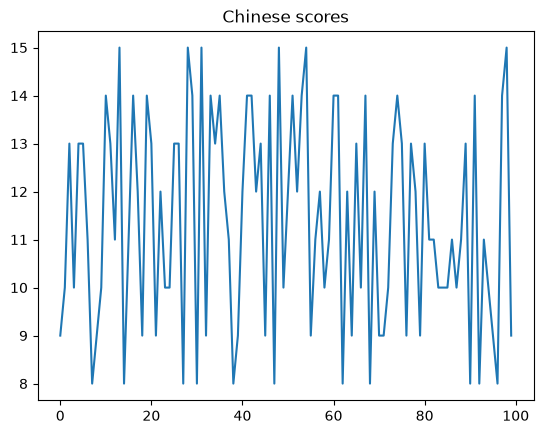

In [10]:
df["國文"].plot(title="Chinese scores")
plt.show()

當然, 在這個例子中, 其實畫 histogram 圖更有意義一點。

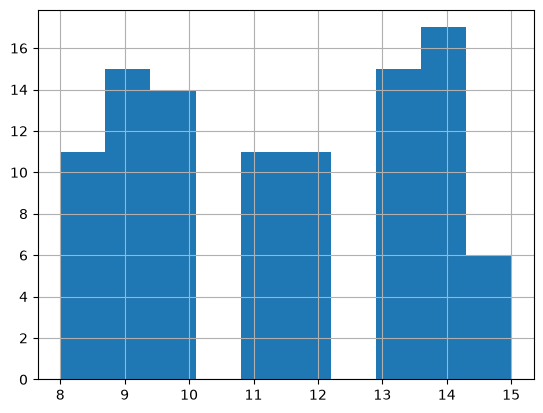

In [11]:
df["國文"].hist(bins=10)
plt.show()

## 3 一些基本的資料分析

算平均。

In [12]:
df.mean(numeric_only=True)

國文    11.39
英文    11.38
數學    11.57
自然    11.03
社會    11.83
dtype: float64

算標準差。

In [13]:
df.std(numeric_only=True)

國文    2.196853
英文    2.273164
數學    2.310516
自然    2.217720
社會    2.486550
dtype: float64

不如就該算的都幫我們算算...

In [14]:
df.describe()

,國文,英文,數學,自然,社會
count,100.000000,100.000000,100.000000,100.00000,100.00000
mean,11.390000,11.380000,11.570000,11.03000,11.83000
std,2.196853,2.273164,2.310516,2.21772,2.48655
min,8.000000,8.000000,8.000000,8.00000,8.00000
25%,9.000000,9.000000,10.000000,9.00000,9.00000
50%,11.000000,11.000000,11.000000,11.00000,12.00000
75%,13.000000,13.000000,14.000000,13.00000,14.00000
max,15.000000,15.000000,15.000000,15.00000,15.00000


有時我們很愛看的相關係數矩陣。

In [15]:
df.corr(numeric_only=True)

,國文,英文,數學,自然,社會
國文,1.000000,0.160158,-0.310899,-0.110236,-0.028421
英文,0.160158,1.000000,0.025656,0.113929,-0.063512
數學,-0.310899,0.025656,1.000000,0.014371,0.041651
自然,-0.110236,0.113929,0.014371,1.000000,-0.156594
社會,-0.028421,-0.063512,0.041651,-0.156594,1.000000


只算兩科間的相關係數當然也可以。

In [16]:
df["國文"].corr(df["英文"])

np.float64(0.16015801596684315)

## 4 增加一行

### 【技巧】

我們增加一行, 加入總級分。

In [17]:
df["總級分"] = df[["國文", "英文", "數學", "自然", "社會"]].sum(axis=1)
df.head()

,姓名,國文,英文,數學,自然,社會,總級分
0,劉俊安,9,10,15,10,13,57
1,胡玉華,10,10,10,8,9,47
2,黃淑婷,13,15,8,11,14,61
3,陳上紫,10,10,8,9,14,51
4,崔靜成,13,12,14,12,13,64


### 【技巧】

有計算的當然也可以的。

In [18]:
df["加權分"] = df["國文"]*0.2 + df["英文"]*0.2 + df["數學"]*0.3 + df["自然"]*0.15 + df["社會"]*0.15
df.head()

,姓名,國文,英文,數學,自然,社會,總級分,加權分
0,劉俊安,9,10,15,10,13,57,11.75
1,胡玉華,10,10,10,8,9,47,9.55
2,黃淑婷,13,15,8,11,14,61,11.75
3,陳上紫,10,10,8,9,14,51,9.85
4,崔靜成,13,12,14,12,13,64,12.95


In [19]:
df.head()

,姓名,國文,英文,數學,自然,社會,總級分,加權分
0,劉俊安,9,10,15,10,13,57,11.75
1,胡玉華,10,10,10,8,9,47,9.55
2,黃淑婷,13,15,8,11,14,61,11.75
3,陳上紫,10,10,8,9,14,51,9.85
4,崔靜成,13,12,14,12,13,64,12.95


## 5 排序和 index 重設

### 【重點】排序的方法

我們依總級分來排序。

In [20]:
df.sort_values("總級分",ascending=False).head()

,姓名,國文,英文,數學,自然,社會,總級分,加權分
80,施雅鈴,13,15,12,13,13,66,13.10
12,李正偉,11,15,11,14,15,66,12.85
54,陳怡潔,15,15,9,15,11,65,12.60
25,蔡亦瑄,13,13,14,13,12,65,13.15
57,胡淳茜,12,15,14,13,11,65,13.20


### 【重點】排序的方法

加權分最高, 同分才看總級分

In [21]:
df.sort_values(["加權分","總級分"],ascending=[False,False]).head()

,姓名,國文,英文,數學,自然,社會,總級分,加權分
57,胡淳茜,12,15,14,13,11,65,13.20
83,李士賢,10,14,15,13,13,65,13.20
37,曾怡君,11,12,15,13,14,65,13.15
25,蔡亦瑄,13,13,14,13,12,65,13.15
36,詹威德,12,13,15,10,14,64,13.10


### 【重點】重設 index

In [22]:
df.reset_index(drop=True).head()

,姓名,國文,英文,數學,自然,社會,總級分,加權分
0,劉俊安,9,10,15,10,13,57,11.75
1,胡玉華,10,10,10,8,9,47,9.55
2,黃淑婷,13,15,8,11,14,61,11.75
3,陳上紫,10,10,8,9,14,51,9.85
4,崔靜成,13,12,14,12,13,64,12.95


## 6 篩出我們要的資料

基本上和 NumPy 的 array 篩法很像。

### 【重點】

找出數學滿級分同學。

In [23]:
df[df["數學"]==15]

,姓名,國文,英文,數學,自然,社會,總級分,加權分
0,劉俊安,9,10,15,10,13,57,11.75
24,陳竹伯,10,12,15,10,14,61,12.50
36,詹威德,12,13,15,10,14,64,13.10
37,曾怡君,11,12,15,13,14,65,13.15
39,段冠廷,9,8,15,12,15,59,11.95
59,芮秋辛,11,10,15,10,8,54,11.40
67,林哲法,14,9,15,10,14,62,12.70
70,葉儀依,9,13,15,8,14,59,12.20
73,吳志遠,13,15,15,8,8,59,12.50
76,周育霖,9,12,15,13,12,61,12.45


### 【重點】

找出數學和英文都滿級分的同學。要注意 `and` 要用 `&`, `or` 要用 `|`。每個條件一定要加弧號。

In [24]:
df[(df["數學"]==15)&(df["英文"]==15)]

,姓名,國文,英文,數學,自然,社會,總級分,加權分
73,吳志遠,13,15,15,8,8,59,12.5


## 7 刪除一行或一列

### 【重點】刪掉一行

我們來刪掉總級分的那行。

In [25]:
df.drop(columns=["總級分"]).head()

,姓名,國文,英文,數學,自然,社會,加權分
0,劉俊安,9,10,15,10,13,11.75
1,胡玉華,10,10,10,8,9,9.55
2,黃淑婷,13,15,8,11,14,11.75
3,陳上紫,10,10,8,9,14,9.85
4,崔靜成,13,12,14,12,13,12.95


### 【重點】改變原有的 DataFrame

我們會發現 `pandas` 很多動作都沒有更改原有的 DataFrame, 真的要改要加入

    inplace=True

In [26]:
df.drop(columns=["總級分"], inplace=True)
df.head()

,姓名,國文,英文,數學,自然,社會,加權分
0,劉俊安,9,10,15,10,13,11.75
1,胡玉華,10,10,10,8,9,9.55
2,黃淑婷,13,15,8,11,14,11.75
3,陳上紫,10,10,8,9,14,9.85
4,崔靜成,13,12,14,12,13,12.95


### 【重點】刪掉一列

刪掉列就是指定要刪去的 index。

In [27]:
df.drop(index=0).head()

,姓名,國文,英文,數學,自然,社會,加權分
1,胡玉華,10,10,10,8,9,9.55
2,黃淑婷,13,15,8,11,14,11.75
3,陳上紫,10,10,8,9,14,9.85
4,崔靜成,13,12,14,12,13,12.95
5,張雅岳,13,12,12,12,8,11.60


In [28]:
df.head()

,姓名,國文,英文,數學,自然,社會,加權分
0,劉俊安,9,10,15,10,13,11.75
1,胡玉華,10,10,10,8,9,9.55
2,黃淑婷,13,15,8,11,14,11.75
3,陳上紫,10,10,8,9,14,9.85
4,崔靜成,13,12,14,12,13,12.95


### 【重點】刪掉一列

通常刪掉符合條件的比較合理 (注意是找到要刪掉的部份, 再找出相對的 index)。

In [29]:
idx = df[df["數學"] < 10].index
print(f"符合條件的索引：{idx.tolist()}")

符合條件的索引：[2, 3, 10, 13, 18, 26, 28, 31, 32, 33, 38, 40, 41, 43, 54, 58, 61, 63, 75, 82, 84, 95, 98]


In [30]:
df.drop(index=idx).head()

,姓名,國文,英文,數學,自然,社會,加權分
0,劉俊安,9,10,15,10,13,11.75
1,胡玉華,10,10,10,8,9,9.55
4,崔靜成,13,12,14,12,13,12.95
5,張雅岳,13,12,12,12,8,11.60
6,梁俊翔,11,13,10,10,14,11.40


## 8 真實股價資料

有個從 `Pandas` 獨立出來的套件叫 `pandas-datareader`, 幾經波折, 先是 Yahoo! 的財務資料不能用, 後來又是 Google 的資料不能用, 不過至少現在看來 Yahoo! 還可以使用。

安裝 `pandas-datareader` 就標準 `conda` 安裝:

    conda install pandas-datareader
    
如果裝過, 但很久沒更新就用:

    conda update pandas-datareader

### 【例子】 分析 Apple 股價

In [65]:
# import pandas_datareader as pdr
# df = pdr.get_data_yahoo('AAPL')

ModuleNotFoundError: No module named 'pandas_datareader'

In [31]:
# 為防止網路有問題, 我們把這個檔案以 aapl.csv 存起來, 可以這樣讀入。
df = pd.read_csv("data/aapl.csv", index_col="Date", parse_dates=True)
df.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2009-12-31,30.447144,30.478571,30.080000,30.104286,26.986492,88102700
2010-01-04,30.490000,30.642857,30.340000,30.572857,27.406532,123432400
2010-01-05,30.657143,30.798571,30.464285,30.625713,27.453915,150476200
2010-01-06,30.625713,30.747143,30.107143,30.138571,27.017223,138040000
2010-01-07,30.250000,30.285715,29.864286,30.082857,26.967278,119282800


In [33]:
# 為防止網路有問題, 我們把這個檔案以 aapl.csv 存起來, 可以這樣讀入。
# df = pd.read_csv('data/aapl.csv', index_col="Date")

In [32]:
df.tail()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2017-12-04,172.479996,172.619995,169.630005,169.800003,169.800003,32542400
2017-12-05,169.059998,171.520004,168.399994,169.639999,169.639999,27350200
2017-12-06,167.500000,170.199997,166.460007,169.009995,169.009995,28560000
2017-12-07,169.029999,170.440002,168.910004,169.320007,169.320007,25673300
2017-12-08,170.490005,171.000000,168.820007,169.369995,169.369995,23173700


#### 只要最後 300 個交易日!

In [34]:
df=df.tail(300).copy()
df.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2016-10-03,112.709999,113.050003,112.279999,112.519997,110.173546,21701800
2016-10-04,113.059998,114.309998,112.629997,113.000000,110.643539,29736800
2016-10-05,113.400002,113.660004,112.690002,113.050003,110.692505,21453100
2016-10-06,113.699997,114.339996,113.129997,113.889999,111.514984,28779300
2016-10-07,114.309998,114.559998,113.510002,114.059998,111.681435,24358400


#### 20 日的移動平均

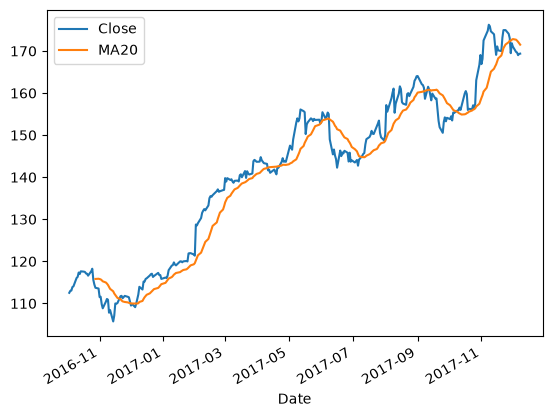

In [35]:
df.Close.plot(label="Close")
df.Close.rolling(20).mean().plot(label="MA20")
plt.legend();plt.show()

In [36]:
df["MA20"]=df.Close.rolling(20).mean()
df.tail()

,Open,High,Low,Close,Adj Close,Volume,MA20
Date,,,,,,,
2017-12-04,172.479996,172.619995,169.630005,169.800003,169.800003,32542400,172.694001
2017-12-05,169.059998,171.520004,168.399994,169.639999,169.639999,27350200,172.463501
2017-12-06,167.500000,170.199997,166.460007,169.009995,169.009995,28560000,172.173501
2017-12-07,169.029999,170.440002,168.910004,169.320007,169.320007,25673300,171.827501
2017-12-08,170.490005,171.000000,168.820007,169.369995,169.369995,23173700,171.502000


#### 20 日和 60 日的移動平均

<Axes: xlabel='Date'>

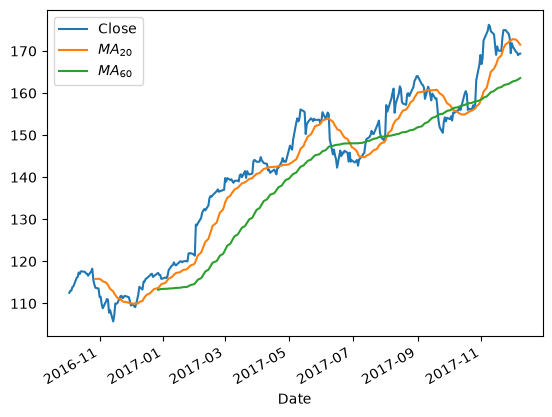

In [37]:
df.Close.plot(legend=True)
df.Close.rolling(20).mean().plot(label="$MA_{20}$",legend=True)
df.Close.rolling(60).mean().plot(label="$MA_{60}$",legend=True)

#### 準備做預測

我們用個非常天真的模型...

![天真股票模型](images/naive.png)

網路上說這是線性的 (可能嗎)!


In [38]:
df["tomorrow"]=df.Close.shift(-1)
df.tail()

,Open,High,Low,Close,Adj Close,Volume,MA20,tomorrow
Date,,,,,,,,
2017-12-04,172.479996,172.619995,169.630005,169.800003,169.800003,32542400,172.694001,169.639999
2017-12-05,169.059998,171.520004,168.399994,169.639999,169.639999,27350200,172.463501,169.009995
2017-12-06,167.500000,170.199997,166.460007,169.009995,169.009995,28560000,172.173501,169.320007
2017-12-07,169.029999,170.440002,168.910004,169.320007,169.320007,25673300,171.827501,169.369995
2017-12-08,170.490005,171.000000,168.820007,169.369995,169.369995,23173700,171.502000,NaN


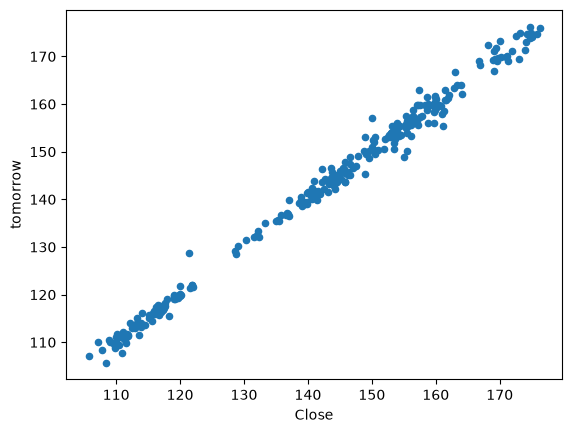

In [39]:
df[["Close","tomorrow"]].dropna().plot.scatter(x="Close",y="tomorrow")
plt.show()

In [40]:
r = df[["Close", "tomorrow"]].corr().iloc[0,1]
print(f"相關係數：{r:.4f}")

相關係數：0.9966


In [41]:
df[["Close","tomorrow"]].dropna().head()

,Close,tomorrow
Date,,
2016-10-03,112.519997,113.000000
2016-10-04,113.000000,113.050003
2016-10-05,113.050003,113.889999
2016-10-06,113.889999,114.059998
2016-10-07,114.059998,116.050003


哦, 真的有點像線性的, 我們之後用線性迴歸試試看。

## 9 手工打造一個 DataFrame*

有時我們用手工打造一個簡單的 DataFrame, 可以更理解整個結構。其實很容易, 一個 DataFrame 基本上就包含兩個主要部份:

* 資料本身: 通常一個二維陣列 (矩陣)
* 行、列的名稱

我們來個簡單的小例子。

In [42]:
mydata = np.random.randn(4,3)

In [43]:
print(mydata)

[[-0.34045484 -0.04828707  0.20994995]
 [-0.59036438  1.66385823 -0.48159261]
 [ 0.51871724  0.73841654 -0.3955442 ]
 [ 1.44834142  0.2576238  -0.23092998]]


把行列的名字放進去, 就成一個 DataFrame。我們列的部份先讓 Python 自己產生。

In [44]:
df2 = pd.DataFrame(mydata, columns=list("ABC"))

In [45]:
df2

,A,B,C
0,-0.340455,-0.048287,0.209950
1,-0.590364,1.663858,-0.481593
2,0.518717,0.738417,-0.395544
3,1.448341,0.257624,-0.230930


#### 兩個表格上下貼起來

我們再來生一個 DataFrame, 再「貼」起來。

In [46]:
df3 = pd.DataFrame(np.random.randn(3,3), columns=list("ABC"))

In [47]:
df3

,A,B,C
0,1.182082,-1.239612,-0.558321
1,-0.021023,0.768350,-0.678350
2,0.392481,-0.574309,-0.672882


In [48]:
pd.concat([df2,df3])

,A,B,C
0,-0.340455,-0.048287,0.209950
1,-0.590364,1.663858,-0.481593
2,0.518717,0.738417,-0.395544
3,1.448341,0.257624,-0.230930
0,1.182082,-1.239612,-0.558321
1,-0.021023,0.768350,-0.678350
2,0.392481,-0.574309,-0.672882


In [49]:
pd.concat([df2,df3]).shape

(7, 3)

前面我們弄得亂七八糟的 index 重設一下。

In [50]:
df4=pd.concat([df2,df3],ignore_index=True)
df4

,A,B,C
0,-0.340455,-0.048287,0.209950
1,-0.590364,1.663858,-0.481593
2,0.518717,0.738417,-0.395544
3,1.448341,0.257624,-0.230930
4,1.182082,-1.239612,-0.558321
5,-0.021023,0.768350,-0.678350
6,0.392481,-0.574309,-0.672882


In [51]:
df4.index

RangeIndex(start=0, stop=7, step=1)

#### 横向的貼

In [52]:
pd.concat([df2,df3],axis=1)

,A,B,C,A,B,C
0,-0.340455,-0.048287,0.209950,1.182082,-1.239612,-0.558321
1,-0.590364,1.663858,-0.481593,-0.021023,0.768350,-0.678350
2,0.518717,0.738417,-0.395544,0.392481,-0.574309,-0.672882
3,1.448341,0.257624,-0.230930,NaN,NaN,NaN


等等, 這大小好像不太對也可以嗎? 答案是可以的!

In [53]:
pd.concat([df2,df3],axis=1).shape

(4, 6)

#### 大一點的例子

我們來做前面「假的」學測資料。首先要有「假的」同學名單, 如果有興趣產生很多名字, 可以用這個服務。

[中文姓名產生器](http://www.richyli.com/name/index.asp)

In [54]:
names = pd.read_csv("data/names.csv", header=None).iloc[:, 0].tolist()
print(f"姓名數量：{len(names)}")

姓名數量：100


In [55]:
print(f"前五個姓名：{names[:5]}")

前五個姓名：['羅雅慧', '王紹尹', '黃季坤', '許正書', '張鈞蓮']


In [58]:
df_grades = pd.DataFrame(np.random.randint(6,16,(100,5)),
                        columns=['國文','英文','數學','社會','自然'])

In [59]:
# names.csv 有 99 筆，所以取相同筆數的成績
df_grades = df_grades.iloc[:len(names)].copy()
df_grades.index = names
df_grades.head()

,國文,英文,數學,社會,自然
羅雅慧,14,13,10,14,9
王紹尹,8,8,9,6,6
黃季坤,15,12,7,15,6
許正書,12,15,15,11,12
張鈞蓮,11,9,12,11,9


In [60]:
df_grades["總級分"]=df_grades.sum(axis=1)
df_grades.head()

,國文,英文,數學,社會,自然,總級分
羅雅慧,14,13,10,14,9,60
王紹尹,8,8,9,6,6,37
黃季坤,15,12,7,15,6,55
許正書,12,15,15,11,12,65
張鈞蓮,11,9,12,11,9,52


In [61]:
df_grades.sort_values("總級分",ascending=False).head(10)

,國文,英文,數學,社會,自然,總級分
許正書,12,15,15,11,12,65
賴郁侑,10,15,13,12,15,65
曾桂甫,13,14,15,8,14,64
宋辛芬,13,12,13,15,11,64
王裕仁,11,15,14,15,9,64
張柏毅,14,11,9,14,15,63
吳建銘,13,15,15,9,11,63
何怡婷,14,15,12,13,9,63
林群喬,13,14,11,10,14,62
姜蕙珮,14,14,11,13,10,62


In [62]:
df_grades.describe()

,國文,英文,數學,社會,自然,總級分
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,10.690000,10.620000,9.980000,10.860000,10.250000,52.400000
std,2.973604,2.751602,2.870892,2.759813,2.782975,6.783819
min,6.000000,6.000000,6.000000,6.000000,6.000000,37.000000
25%,8.000000,8.000000,7.000000,9.000000,8.000000,48.000000
50%,11.000000,10.500000,10.000000,11.000000,10.000000,53.500000
75%,13.250000,13.000000,12.000000,13.000000,12.250000,57.000000
max,15.000000,15.000000,15.000000,15.000000,15.000000,65.000000


In [63]:
df_grades[df_grades["數學"]==15]

,國文,英文,數學,社會,自然,總級分
許正書,12,15,15,11,12,65
吳家銘,6,9,15,13,8,51
吳宜平,13,12,15,11,9,60
陳俊卿,9,7,15,15,9,55
吳建銘,13,15,15,9,11,63
曾桂甫,13,14,15,8,14,64
林佳霖,9,12,15,9,15,60
胡筱芸,14,6,15,9,12,56


In [64]:
df_grades.corr(numeric_only=True)

,國文,英文,數學,社會,自然,總級分
國文,1.000000,0.113847,-0.006650,0.091895,-0.010070,0.514955
英文,0.113847,1.000000,0.088536,0.115297,-0.065294,0.513103
數學,-0.006650,0.088536,1.000000,0.124581,0.118209,0.555370
社會,0.091895,0.115297,0.124581,1.000000,-0.201876,0.463775
自然,-0.010070,-0.065294,0.118209,-0.201876,1.000000,0.347237
總級分,0.514955,0.513103,0.555370,0.463775,0.347237,1.000000
